# Environment check

Run this notebook from top to bottom after selecting this project's `.venv` kernel in VS Code. These cells check which Python is running, confirm the required packages load, verify a repeatable Bernoulli simulation, and display a plot. They do not download football data or train a model.

The Bernoulli example treats each shot as an independent trial with its own scoring probability. Per-shot probabilities do not need to sum to 1; each must be between 0 and 1.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import seaborn as sns
import ipykernel

print(f"Python executable: {sys.executable}")
print(f"Python version: {sys.version.split()[0]}")
print(f"Project environment prefix: {sys.prefix}")

package_versions = {
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "ipykernel": ipykernel.__version__,
}
for package_name, package_version in package_versions.items():
    print(f"{package_name}: {package_version}")


Python executable: e:\dev-work\daniels_vision\.venv\Scripts\python.exe
Python version: 3.14.7
Project environment prefix: e:\dev-work\daniels_vision\.venv
NumPy: 2.5.4
pandas: 3.0.6
SciPy: 1.18.1
scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
ipykernel: 7.4.0


In [2]:
from pathlib import Path
import sys

starting_directory = Path.cwd().resolve()
search_locations = (starting_directory, *starting_directory.parents)
project_root = next(
    (
        folder
        for folder in search_locations
        if (folder / ".venv").is_dir() and (folder / "README.md").is_file()
    ),
    None,
)
assert project_root is not None, (
    "Could not find the project folder. Open this project in VS Code and select its notebook kernel."
)
expected_environment = (project_root / ".venv").resolve()
active_environment = Path(sys.prefix).resolve()

print(f"Notebook working directory: {starting_directory}")
print(f"Project root:               {project_root}")
print(f"Expected environment:       {expected_environment}")
print(f"Active Python environment:  {active_environment}")

assert active_environment == expected_environment, (
    "VS Code is using a different Python environment. "
    "Select this project's .venv Python environment as the notebook kernel."
)
print("Environment check passed.")


Notebook working directory: E:\dev-work\daniels_vision\notebooks
Project root:               E:\dev-work\daniels_vision
Expected environment:       E:\dev-work\daniels_vision\.venv
Active Python environment:  E:\dev-work\daniels_vision\.venv
Environment check passed.


In [3]:
import numpy as np

shot_probabilities = np.array([0.10, 0.30, 0.60])
assert np.all((shot_probabilities >= 0) & (shot_probabilities <= 1))

first_generator = np.random.default_rng(seed=42)
second_generator = np.random.default_rng(seed=42)
simulated_goals = first_generator.binomial(n=1, p=shot_probabilities)
repeated_goals = second_generator.binomial(n=1, p=shot_probabilities)

print(f"Shot probabilities: {shot_probabilities}")
print(f"One simulated result: {simulated_goals}")

assert simulated_goals.shape == shot_probabilities.shape
assert np.isin(simulated_goals, [0, 1]).all()
assert np.array_equal(simulated_goals, repeated_goals)
print("Probability range and repeatability checks passed.")


Shot probabilities: [0.1 0.3 0.6]
One simulated result: [0 0 0]
Probability range and repeatability checks passed.


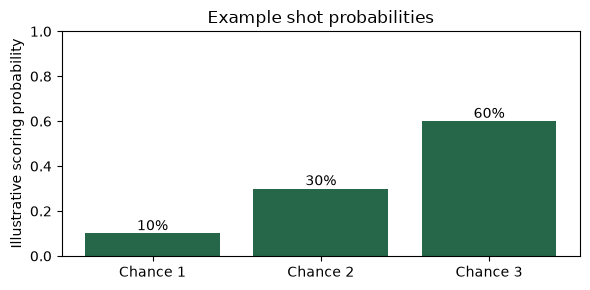

In [4]:
import matplotlib.pyplot as plt
import numpy as np

shot_labels = ["Chance 1", "Chance 2", "Chance 3"]
fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(shot_labels, shot_probabilities, color="#276749")
ax.set_ylim(0, 1)
ax.set_ylabel("Illustrative scoring probability")
ax.set_title("Example shot probabilities")
ax.bar_label(bars, labels=[f"{p:.0%}" for p in shot_probabilities])
fig.tight_layout()
plt.show()
